In [13]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

In [14]:
df = pd.read_csv('../Iris.csv')
# O df original tem 5 colunas (4 medias + a espécie correspondente)
df = df.drop(columns=['Id'])

# Separando X e y
# Como o df original não foi alterado, a coluna 'Species' ainda existe nele!
# y armazena/recebe a coluna 'Species' do df original
# O X é uma cópia sem a coluna 'Species'
X = df.drop(columns=['Species']) # Features
y = df['Species'] # Target

In [15]:
# Dividindo em treino e teste (80% treino, 20% teste)
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=42, stratify=y)

In [16]:
print(f"Total de amostras no X: {len(X)}")
print(f"Amostras de treino (X_train): {len(X_train)}")
print(f"Amostras de teste (X_test): {len(X_test)}")

Total de amostras no X: 150
Amostras de treino (X_train): 120
Amostras de teste (X_test): 30


In [17]:
# Criando a linha de montagem
# O 'scaler' vai padronizar as medidas (para a Sépala não ofuscar a Pétala)
# O 'knn' vai usar a distância entre os vizinhos para classificar
modelo_pipeline = Pipeline([('scaler', StandardScaler()),('knn', KNeighborsClassifier(n_neighbors=3))])

# Treinando (fit) com os dados de treino
modelo_pipeline.fit(X_train, y_train)

# Prevendo (Predict) com os dados de teste (que o modelo nuna viu)
y_pred = modelo_pipeline.predict(X_test)

# Avaliando a acurácia
acuracia = accuracy_score(y_test, y_pred)
print(f"Acurácia do modelo: {acuracia * 100:.2f}%")

Acurácia do modelo: 93.33%


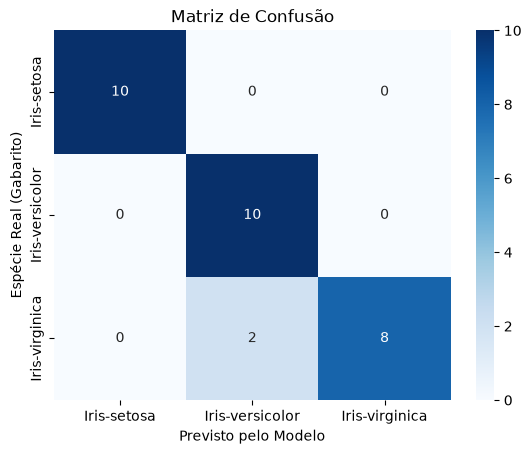

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.83      1.00      0.91        10
 Iris-virginica       1.00      0.80      0.89        10

       accuracy                           0.93        30
      macro avg       0.94      0.93      0.93        30
   weighted avg       0.94      0.93      0.93        30



In [18]:
#1. Matriz de Confusão
cm = confusion_matrix(y_test, y_pred, labels=modelo_pipeline.classes_)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=modelo_pipeline.classes_, 
            yticklabels=modelo_pipeline.classes_)
plt.xlabel('Previsto pelo Modelo')
plt.ylabel('Espécie Real (Gabarito)')
plt.title('Matriz de Confusão')
plt.show()

# 2. Relatório de Classificação
print(classification_report(y_test, y_pred))

In [19]:
df.head() # mostra as primeiras 5 linhas

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [20]:
df.info() # mostra os tipos de dados e se há valores nulos

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   SepalLengthCm  150 non-null    float64
 1   SepalWidthCm   150 non-null    float64
 2   PetalLengthCm  150 non-null    float64
 3   PetalWidthCm   150 non-null    float64
 4   Species        150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB


In [21]:
df.describe() # mostra a média, desvio padrão, min, max...

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667
std,0.828066,0.433594,1.764420,0.763161
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


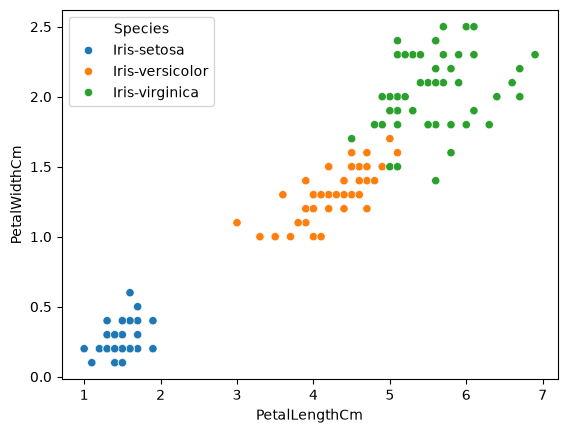

In [22]:
sns.scatterplot(data=df, x='PetalLengthCm', y='PetalWidthCm', hue='Species')
plt.show()

Observando o gráfico, percebe-se que não há uma linha reta que separe perfeitamente as 3 cores (espécies). 
*Também há de registrar-se de que a coluna ID não tem alguma relação com o tamanho ou espécie.*

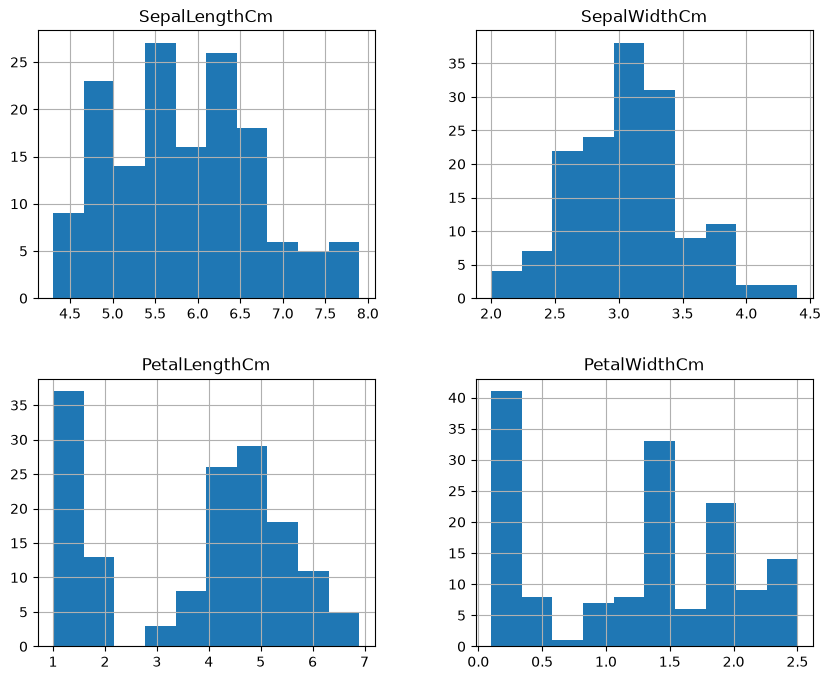

In [23]:
df.hist(figsize=(10,8))
plt.show()

Observando os gráficos gerados, os dados apresentam-se como uma montanha centrada no que refere-se a 'SepalLenghtCm', 'SepalWidhtCm'.

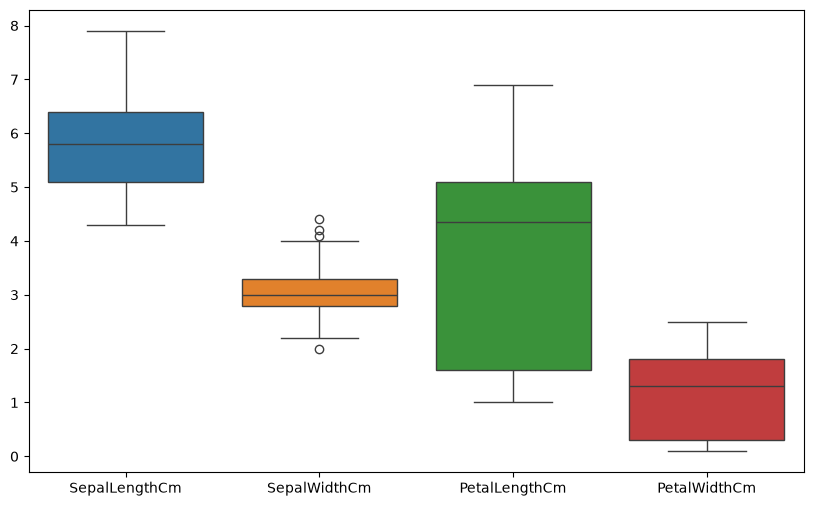

In [24]:
# boxplot para ver outiliers
plt.figure(figsize=(10,6))
sns.boxplot(data=df.drop(columns=['Species']))
plt.show()